# Linear Model Diagnostics: Failure Analysis and Ridge Regularization

Two questions about the linear models from notebook 02.

1. **Where and why does linear regression fail?** Its average validation RMSE (about 2.9 for heating) hides where the errors come from. Out-of-fold predictions are broken down by building height and load level, and a sequence of diagnostic models tests which missing structure explains the errors.
2. **Why does ridge regression not improve on linear regression?** Ridge is the standard response to collinear features, and these features are exactly collinear. An alpha sweep shows how validation error and coefficient stability change with the penalty.

All results use the shared seed-42 five-fold cross-validation on the development set. The held-out test set is not used.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RF_SEEDS, TARGET_COLUMNS
from src.data import create_dev_test_split, load_data, make_design_groups
from src.evaluation import get_cv, regression_metrics
from src.experiments import select_features
from src.reporting import TARGET_LABELS

pd.set_option("display.max_colwidth", None)

TABLES = project_root / "results" / "tables"
FIGURES = project_root / "results" / "figures"

df = load_data()
X_dev, X_test, y_dev, y_test = create_dev_test_split(df)
folds = list(get_cv().split(X_dev))

HEIGHT_LABELS = {3.5: "3.5 m (one story)", 7.0: "7 m (two stories)"}
height = X_dev["overall_height"]

print("Development rows:", len(X_dev))
print("Rows per height:", height.value_counts().sort_index().to_dict())

Development rows: 614
Rows per height: {3.5: 312, 7.0: 302}


# Part 1: Failure analysis

## Out-of-fold predictions

Each development building is predicted once, by the model trained on the four folds that do not contain it. Three models are compared:

- **Linear (8 features):** linear regression with all features.
- **Linear (4, forward):** linear regression on 4 forward-selected features, chosen inside each training fold (the best reduced linear model from notebook 02).
- **Random forest (reference):** the untuned 100-tree baseline from notebook 03 with seed 0, included only as a reference point for where a flexible model still makes errors.

In [2]:
oof_rows = []

for target in TARGET_COLUMNS:
    y = y_dev[target]

    for fold, (train_idx, val_idx) in enumerate(folds, start=1):
        X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
        y_train = y.iloc[train_idx]

        forward_cols, _ = select_features(X_train, y_train, 4, "forward")

        predictions = {
            "linear_8": LinearRegression().fit(X_train, y_train).predict(X_val),
            "linear_4_forward": (
                LinearRegression()
                .fit(X_train[forward_cols], y_train)
                .predict(X_val[forward_cols])
            ),
            "random_forest_ref": (
                RandomForestRegressor(n_estimators=100, random_state=RF_SEEDS[0], n_jobs=-1)
                .fit(X_train, y_train)
                .predict(X_val)
            ),
        }

        for model_name, predicted in predictions.items():
            oof_rows.append(pd.DataFrame({
                "row_index": X_val.index,
                "target": target,
                "model": model_name,
                "fold": fold,
                "overall_height": X_val["overall_height"].to_numpy(),
                "actual": y.iloc[val_idx].to_numpy(),
                "predicted": predicted,
            }))

oof = pd.concat(oof_rows, ignore_index=True)
oof["residual"] = oof["predicted"] - oof["actual"]

oof.to_csv(TABLES / "linear_oof_predictions.csv", index=False)
print("Out-of-fold predictions:", len(oof), "rows")

Out-of-fold predictions: 3684 rows


### Check: matches the notebook 02 fold scores

Mean fold RMSE of the 8-feature linear model should equal the notebook 02 result.

In [3]:
fold_rmse = (
    oof.query("model == 'linear_8'")
    .groupby(["target", "fold"])
    .apply(lambda g: regression_metrics(g["actual"], g["predicted"])["rmse"], include_groups=False)
    .groupby("target").mean()
)
saved = (
    pd.read_csv(TABLES / "linear_feature_ablation_cv.csv")
    .query("n_features == 8")
    .groupby("target")["rmse"].mean()
)
print("Largest difference:", float((fold_rmse - saved).abs().max()))

Largest difference: 0.0


## Error by building height

The dataset contains only two heights. RMSE here is computed over all out-of-fold predictions in each group (pooled, not averaged over folds). *Mean residual* is predicted − actual: positive means over-prediction.

In [4]:
def group_errors(data, by):
    return (
        data.groupby(by, sort=False)
        .apply(
            lambda g: pd.Series({
                "n": len(g),
                "rmse": np.sqrt(np.mean(g["residual"] ** 2)),
                "mae": np.mean(np.abs(g["residual"])),
                "mean_residual": g["residual"].mean(),
            }),
            include_groups=False,
        )
    )

overall = group_errors(oof, ["target", "model"]).assign(overall_height="all")
by_height = group_errors(oof, ["target", "model", "overall_height"]).reset_index(level="overall_height")

height_table = (
    pd.concat([by_height, overall])
    .reset_index()
    .pivot_table(index=["target", "model"], columns="overall_height", values="rmse", sort=False)
    [[3.5, 7.0, "all"]]
)
height_table["tall / short"] = height_table[7.0] / height_table[3.5]

height_table.round(3)

overall_height                    3.5    7.0    all  tall / short
target       model                                               
heating_load linear_8           1.599  3.834  2.920         2.398
             linear_4_forward   1.754  3.858  2.981         2.199
             random_forest_ref  0.299  0.678  0.521         2.264
cooling_load linear_8           1.838  4.207  3.228         2.289
             linear_4_forward   1.956  4.177  3.244         2.135
             random_forest_ref  0.358  2.445  1.733         6.821

### Share of the largest errors that come from tall buildings

In [5]:
worst_share_rows = []

for (target, model_name), g in oof.groupby(["target", "model"], sort=False):
    cutoff = g["residual"].abs().quantile(0.95)
    worst = g[g["residual"].abs() >= cutoff]
    worst_share_rows.append({
        "target": target,
        "model": model_name,
        "worst 5% rows": len(worst),
        "share tall": (worst["overall_height"] == 7.0).mean(),
    })

pd.DataFrame(worst_share_rows).round(2)

,target,model,worst 5% rows,share tall
0,heating_load,linear_8,31,1.00
1,heating_load,linear_4_forward,31,1.00
2,heating_load,random_forest_ref,31,0.94
3,cooling_load,linear_8,31,1.00
4,cooling_load,linear_4_forward,31,1.00
5,cooling_load,random_forest_ref,31,1.00


## Systematic bias inside each height group

If the errors were random, the mean residual would be near zero at every load level. Instead, within tall buildings the 8-feature linear model over-predicts the lowest loads and under-predicts the highest: its predictions are squeezed toward the middle of the group. This is a structural error, not noise.

In [6]:
lin = oof.query("model == 'linear_8'").copy()
lin["load_quartile"] = (
    lin.groupby(["target", "overall_height"])["actual"]
    .transform(lambda s: pd.qcut(s, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]))
)

bias_table = (
    lin.pivot_table(
        index=["target", "overall_height"],
        columns="load_quartile",
        values="residual",
        aggfunc="mean",
        observed=True,
    )
    .reindex(columns=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    .reindex(pd.MultiIndex.from_product(
        [TARGET_COLUMNS, [3.5, 7.0]], names=["target", "overall_height"]
    ))
)
bias_table.round(2)

load_quartile                Q1 (lowest)    Q2    Q3  Q4 (highest)
target       overall_height                                       
heating_load 3.5                   -0.76  0.24  0.99         -0.50
             7.0                    3.72  0.92 -0.89         -3.75
cooling_load 3.5                    0.07  0.59  0.93         -1.57
             7.0                    4.11  0.93 -0.93         -4.21

## Why: building shape does not act like a straight line

The 768 buildings come from only 12 shapes, 6 at each height. Every geometric feature (relative compactness, surface, wall, and roof area) is fixed by the shape, so a linear model can only give load a straight-line trend across shapes. The mean load per shape shows there is no such trend: within the tall group, loads rise, fall, and rise again as compactness increases.

In [7]:
shape_table = (
    df.groupby(["overall_height", "relative_compactness"])
    .agg(
        surface_area=("surface_area", "first"),
        wall_area=("wall_area", "first"),
        roof_area=("roof_area", "first"),
        heating_load=("heating_load", "mean"),
        cooling_load=("cooling_load", "mean"),
    )
)
shape_table.round(1)

surface_area  wall_area  roof_area  \
overall_height relative_compactness                                       
3.5            0.62                         808.5      367.5      220.5   
               0.64                         784.0      343.0      220.5   
               0.66                         759.5      318.5      220.5   
               0.69                         735.0      294.0      220.5   
               0.71                         710.5      269.5      220.5   
               0.74                         686.0      245.0      220.5   
7.0            0.76                         661.5      416.5      122.5   
               0.79                         637.0      343.0      147.0   
               0.82                         612.5      318.5      147.0   
               0.86                         588.0      294.0      147.0   
               0.90                         563.5      318.5      122.5   
               0.98                         514.5      294.0      110.2   

                                     heating_load  cooling_load  
overall_height relative_compactness                              
3.5            0.62                          14.3          15.2  
               0.64                          16.6          20.2  
               0.66                          12.8          15.9  
               0.69                          12.4          15.2  
               0.71                          12.0          15.0  
               0.74                          11.9          14.8  
7.0            0.76                          35.7          36.4  
               0.79                          38.6          40.2  
               0.82                          25.6          28.0  
               0.86                          28.6          30.9  
               0.90                          31.6          33.8  
               0.98                          27.6          29.2

Glazing also has a non-linear effect: going from no windows (0) to 10% glazing raises heating load far more than each later step.

In [8]:
df.groupby(["overall_height", "glazing_area"])[TARGET_COLUMNS].mean().unstack(0).round(2)

heating_load        cooling_load       
overall_height          3.5    7.0          3.5    7.0
glazing_area                                          
0.00                   7.59  20.98        12.59  26.82
0.10                  12.00  28.72        14.94  30.93
0.25                  13.58  31.93        16.19  33.60
0.40                  15.58  35.24        17.78  36.04

## Testing the explanation: diagnostic models

If the linear model fails because of missing structure rather than missing information, giving a linear model that structure should remove most of the error. Each row below adds one piece and is evaluated with the same out-of-fold procedure. These are **diagnostics, not candidate models**: they are hand-built from knowledge of this dataset's 12 shapes and would not apply to a new shape.

| Step | Model | What it adds |
|---|---|---|
| 1 | Linear, 8 raw features | (notebook 02 model) |
| 2 | Separate linear model per height | Feature effects can differ between one- and two-story buildings |
| 3 | Shape as a category | One level per shape (12) instead of a straight-line trend in geometry |
| 4 | + shape × glazing area | Glazing effect can differ by shape |
| 5 | + glazing distribution as a category | Distribution 0 (no windows) and the five layouts are treated separately |

In [9]:
def diagnostic_design(X, step):
    shape = X["relative_compactness"].round(2).astype(str)
    shape_dummies = pd.get_dummies(shape, prefix="shape", dtype=float)
    shape_x_glazing = shape_dummies.mul(X["glazing_area"], axis=0).add_suffix("_x_glazing")

    if step == 3:
        parts = [shape_dummies, X[["glazing_area", "glazing_area_distribution", "orientation"]]]
    elif step == 4:
        parts = [shape_dummies, shape_x_glazing, X[["glazing_area_distribution", "orientation"]]]
    elif step == 5:
        distribution = pd.get_dummies(X["glazing_area_distribution"], prefix="dist", dtype=float)
        parts = [shape_dummies, shape_x_glazing, distribution, X[["orientation"]]]
    else:
        raise ValueError(step)

    return pd.concat(parts, axis=1)


def oof_predict(step, y):
    predictions = pd.Series(np.nan, index=y.index)

    for train_idx, val_idx in folds:
        X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
        y_train = y.iloc[train_idx]

        if step == 1:
            predictions.iloc[val_idx] = LinearRegression().fit(X_train, y_train).predict(X_val)
        elif step == 2:
            fold_predictions = np.empty(len(val_idx))
            for h in (3.5, 7.0):
                train_mask = X_train["overall_height"] == h
                val_mask = (X_val["overall_height"] == h).to_numpy()
                fold_predictions[val_mask] = (
                    LinearRegression()
                    .fit(X_train[train_mask], y_train[train_mask])
                    .predict(X_val[val_mask])
                )
            predictions.iloc[val_idx] = fold_predictions
        else:
            design = diagnostic_design(X_dev, step)
            predictions.iloc[val_idx] = (
                LinearRegression()
                .fit(design.iloc[train_idx], y_train)
                .predict(design.iloc[val_idx])
            )

    return predictions


STEP_NAMES = {
    1: "1. Linear, 8 raw features",
    2: "2. Separate model per height",
    3: "3. Shape as a category",
    4: "4. + shape x glazing area",
    5: "5. + glazing distribution category",
}

diag_rows = []

for target in TARGET_COLUMNS:
    y = y_dev[target]
    for step, name in STEP_NAMES.items():
        residual = oof_predict(step, y) - y
        diag_rows.append({
            "target": target,
            "step": name,
            "all": np.sqrt(np.mean(residual ** 2)),
            "short (3.5 m)": np.sqrt(np.mean(residual[height == 3.5] ** 2)),
            "tall (7 m)": np.sqrt(np.mean(residual[height == 7.0] ** 2)),
        })

    rf = oof.query("target == @target and model == 'random_forest_ref'")
    diag_rows.append({
        "target": target,
        "step": "Random forest (reference)",
        "all": np.sqrt(np.mean(rf["residual"] ** 2)),
        "short (3.5 m)": np.sqrt(np.mean(rf.loc[rf["overall_height"] == 3.5, "residual"] ** 2)),
        "tall (7 m)": np.sqrt(np.mean(rf.loc[rf["overall_height"] == 7.0, "residual"] ** 2)),
    })

diagnostics = pd.DataFrame(diag_rows)
diagnostics.to_csv(TABLES / "linear_failure_diagnostics.csv", index=False)
diagnostics.round(3)

,target,step,all,short (3.5 m),tall (7 m)
0,heating_load,"1. Linear, 8 raw features",2.920,1.599,3.834
1,heating_load,2. Separate model per height,2.313,1.325,3.010
2,heating_load,3. Shape as a category,1.360,1.118,1.570
3,heating_load,4. + shape x glazing area,1.086,0.807,1.313
4,heating_load,5. + glazing distribution category,0.542,0.435,0.634
5,heating_load,Random forest (reference),0.521,0.299,0.678
6,cooling_load,"1. Linear, 8 raw features",3.228,1.838,4.207
7,cooling_load,2. Separate model per height,2.848,1.708,3.671
8,cooling_load,3. Shape as a category,1.805,0.825,2.433
9,cooling_load,4. + shape x glazing area,1.706,0.568,2.364


## A floor no model breaks: tall-building cooling load

Every model, including the random forest, keeps a tall-building cooling RMSE of about 2.3–2.4. Each design appears at up to four orientations. Orientation barely changes heating load, but for tall buildings it changes cooling load by a few units in a way that differs from design to design (the average orientation effect is close to zero). The spread among orientation copies of the same design is about the size of the remaining error, so that error is a limit of what these eight features can explain, not a failure specific to linear models.

In [10]:
design = make_design_groups(df)
spread_rows = []

for target in TARGET_COLUMNS:
    within_var = df.groupby(design)[target].var(ddof=1)
    design_height = df.groupby(design)["overall_height"].first()
    for h in (3.5, 7.0):
        spread_rows.append({
            "target": target,
            "overall_height": h,
            "std across orientation copies": np.sqrt(within_var[design_height == h].mean()),
        })

display(pd.DataFrame(spread_rows).round(3))

print("Mean load by orientation (tall buildings):")
df.query("overall_height == 7.0").groupby("orientation")[TARGET_COLUMNS].mean().round(2)

,target,overall_height,std across orientation copies
0,heating_load,3.5,0.218
1,heating_load,7.0,0.537
2,cooling_load,3.5,0.265
3,cooling_load,7.0,2.501


Mean load by orientation (tall buildings):


,heating_load,cooling_load
orientation,,
2,31.30,33.23
3,31.39,32.60
4,31.23,32.84
5,31.18,33.75


## Worst-predicted buildings (8-feature linear model)

In [11]:
worst = (
    oof.query("model == 'linear_8'")
    .assign(abs_residual=lambda d: d["residual"].abs())
    .sort_values("abs_residual", ascending=False)
    .groupby("target", sort=False)
    .head(10)
    .merge(X_dev, left_on="row_index", right_index=True, suffixes=("", "_x"))
    [["target", "actual", "predicted", "residual", "overall_height", "relative_compactness",
      "glazing_area", "glazing_area_distribution", "orientation"]]
)
worst.round(2)

,target,actual,predicted,residual,overall_height,relative_compactness,glazing_area,glazing_area_distribution,orientation
1892,cooling_load,48.03,36.66,-11.37,7.0,0.79,0.40,2,5
2225,cooling_load,45.48,34.23,-11.25,7.0,0.79,0.25,4,3
2697,cooling_load,43.12,31.94,-11.18,7.0,0.79,0.10,3,2
1891,cooling_load,45.52,34.44,-11.08,7.0,0.79,0.25,1,5
2289,cooling_load,45.13,34.08,-11.05,7.0,0.79,0.25,3,2
2624,cooling_load,47.59,36.60,-10.99,7.0,0.79,0.40,4,3
2683,cooling_load,45.28,34.51,-10.77,7.0,0.79,0.25,5,4
1936,cooling_load,43.14,32.54,-10.60,7.0,0.79,0.10,5,4
2634,cooling_load,42.86,32.28,-10.58,7.0,0.79,0.10,2,5
3014,cooling_load,47.01,36.45,-10.56,7.0,0.79,0.40,5,4


## Figure C: where linear regression fails

Out-of-fold predictions of the 8-feature linear model, colored by building height. One-story buildings sit near the diagonal. Two-story buildings form a wider band that is too flat: low loads are over-predicted and high loads under-predicted.

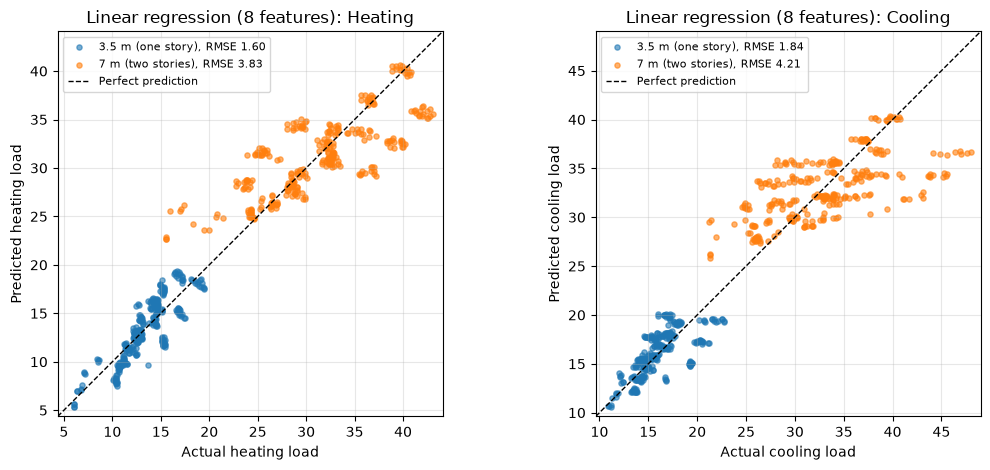

In [12]:
colors = {3.5: "tab:blue", 7.0: "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, target in zip(axes, TARGET_COLUMNS):
    data = oof.query("target == @target and model == 'linear_8'")

    for h, color in colors.items():
        subset = data[data["overall_height"] == h]
        rmse = np.sqrt(np.mean(subset["residual"] ** 2))
        ax.scatter(
            subset["actual"], subset["predicted"],
            s=14, alpha=0.6, color=color,
            label=f"{HEIGHT_LABELS[h]}, RMSE {rmse:.2f}",
        )

    low = min(data["actual"].min(), data["predicted"].min()) - 1
    high = max(data["actual"].max(), data["predicted"].max()) + 1
    ax.plot([low, high], [low, high], "k--", linewidth=1, label="Perfect prediction")

    ax.set(
        xlim=(low, high), ylim=(low, high),
        xlabel=f"Actual {TARGET_LABELS[target].lower()} load",
        ylabel=f"Predicted {TARGET_LABELS[target].lower()} load",
        title=f"Linear regression (8 features): {TARGET_LABELS[target]}",
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "linear_failure_analysis.png", dpi=200, bbox_inches="tight")
plt.show()

### Paper version of Figure C

Sized for one column of the IEEE two-column format (3.5 in wide) and saved as a vector PDF, so text stays readable at print size.

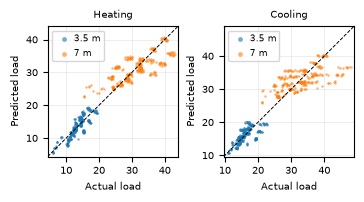

In [13]:
with plt.rc_context({"font.size": 7, "axes.titlesize": 7.5, "legend.fontsize": 6.5}):
    fig, axes = plt.subplots(1, 2, figsize=(3.5, 1.95))

    for ax, target in zip(axes, TARGET_COLUMNS):
        data = oof.query("target == @target and model == 'linear_8'")
        for h, color in colors.items():
            subset = data[data["overall_height"] == h]
            ax.scatter(subset["actual"], subset["predicted"], s=3, alpha=0.6, color=color,
                       linewidths=0, label=f"{h:g} m")

        low = min(data["actual"].min(), data["predicted"].min()) - 1
        high = max(data["actual"].max(), data["predicted"].max()) + 1
        ax.plot([low, high], [low, high], "k--", linewidth=0.7)
        ax.set(xlim=(low, high), ylim=(low, high), title=TARGET_LABELS[target],
               xlabel="Actual load", ylabel="Predicted load")
        ax.set_aspect("equal")
        ax.grid(alpha=0.3, linewidth=0.5)
        ax.legend(loc="upper left", handletextpad=0.1, borderpad=0.3, markerscale=2)

    fig.tight_layout(pad=0.3, w_pad=0.8)
    fig.savefig(FIGURES / "linear_failure_analysis_paper.pdf", bbox_inches="tight")
    plt.show()

### Supporting figure: what removes the linear model's error

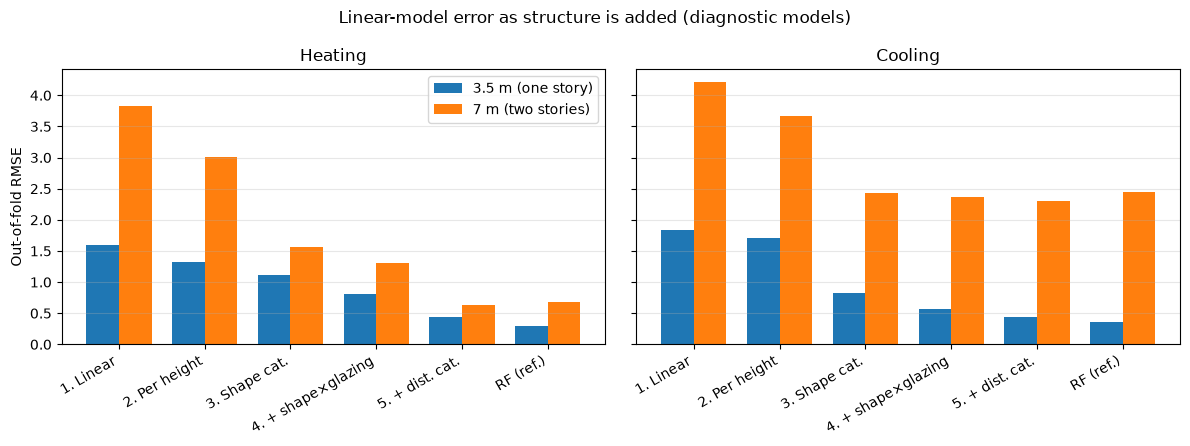

In [14]:
plot_steps = list(STEP_NAMES.values()) + ["Random forest (reference)"]
short_labels = ["1. Linear", "2. Per height", "3. Shape cat.", "4. + shape×glazing", "5. + dist. cat.", "RF (ref.)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
width = 0.38
x = np.arange(len(plot_steps))

for ax, target in zip(axes, TARGET_COLUMNS):
    data = diagnostics.set_index(["target", "step"]).loc[target].loc[plot_steps]
    ax.bar(x - width / 2, data["short (3.5 m)"], width, color=colors[3.5], label=HEIGHT_LABELS[3.5])
    ax.bar(x + width / 2, data["tall (7 m)"], width, color=colors[7.0], label=HEIGHT_LABELS[7.0])
    ax.set_xticks(x, short_labels, rotation=30, ha="right")
    ax.set_title(TARGET_LABELS[target])
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Out-of-fold RMSE")
axes[0].legend()
fig.suptitle("Linear-model error as structure is added (diagnostic models)")
fig.tight_layout()
fig.savefig(FIGURES / "linear_failure_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()

## Failure-analysis findings

1. **The errors are concentrated in tall buildings.** Tall-building RMSE is about 2.4 times the short-building RMSE (heating 3.83 vs. 1.60; cooling 4.21 vs. 1.84), and every one of the worst 5% of linear predictions is a tall building. The 4-feature forward-selected model fails in the same place, so reducing the feature count does not change *where* linear regression fails.
2. **The errors are systematic, not random.** Within tall buildings, the lowest-load quarter is over-predicted by about 3.7 (heating) and 4.1 (cooling) on average, and the highest-load quarter is under-predicted by about the same amount.
3. **The cause is the form of the relationship, not missing information.** The geometric features describe only 12 shapes, and load is not a straight-line function of them: among tall buildings, compactness 0.79 has the highest mean heating load (38.6) and 0.82 the lowest (25.6). The worst linear predictions are exactly these two shapes. Glazing also acts non-linearly (no windows vs. any windows is the largest step).
4. **Adding that structure to a linear model removes the error.** A separate model per height helps only partly (heating 2.92 → 2.31). Treating shape as a category gives 1.36; letting the glazing effect differ by shape gives 1.09; treating glazing distribution as a category gives 0.54, matching the random forest (0.52). The eight features therefore contain enough information for random-forest-level heating accuracy. Linear regression falls short because the effects are non-linear and interact (shape × height × glazing), which is the structure a random forest learns automatically through its splits.
5. **Tall-building cooling load has an error floor for every model.** All diagnostic models and the random forest stay near 2.3–2.4 RMSE on tall-building cooling load, close to the 2.5 spread among orientation copies of the same design. This is a limit of the available features rather than a linear-model failure, and it is where most of the random forest's remaining cooling error lies (tall/short RMSE ratio 6.8).

**Caveat.** The diagnostic models use knowledge of this dataset's 12 shapes and are not proposed as predictors. With only 12 shapes, no cross-validation scheme here can test how any model would handle a building shape it has never seen.

# Part 2: Ridge regularization

## The features are exactly collinear

Surface area equals wall area plus twice the roof area for every building, so the 8 features carry only 7 independent directions. Ordinary least squares then has no unique solution: $X^\top X$ is singular. Scikit-learn's `LinearRegression` still returns one (the minimum-norm least-squares solution), which is why it did not fail in notebook 02. Ridge adds $\alpha I$ to $X^\top X$, which makes the solution unique for any $\alpha > 0$:

$$\hat\beta_{\text{ridge}} = (X^\top X + \alpha I)^{-1} X^\top y.$$

In [15]:
X_scaled = StandardScaler().fit_transform(X_dev)

identity_gap = (X_dev["surface_area"] - (X_dev["wall_area"] + 2 * X_dev["roof_area"])).abs().max()
eigenvalues = np.linalg.eigvalsh(X_scaled.T @ X_scaled / len(X_scaled))[::-1]

print("max |surface_area - (wall_area + 2 * roof_area)|:", identity_gap)
print("Rank of development feature matrix:", np.linalg.matrix_rank(X_dev.to_numpy()), "of", X_dev.shape[1])
print(f"Condition number (standardized features): {np.linalg.cond(X_scaled):.2e}")
print("\nEigenvalues of the standardized feature correlation matrix:")
print(pd.Series(eigenvalues, index=range(1, 9)).round(6).to_string())

max |surface_area - (wall_area + 2 * roof_area)|: 0.0
Rank of development feature matrix: 7 of 8
Condition number (standardized features): 3.06e+15

Eigenvalues of the standardized feature correlation matrix:
1    3.706235
2    1.251335
3    1.197715
4    0.995961
5    0.792066
6    0.052207
7    0.004482
8   -0.000000


## Alpha sweep

Ridge with all 8 standardized features, for 17 values of alpha from $10^{-4}$ to $10^4$, on the shared five folds. For each alpha the validation RMSE and the fitted (standardized) coefficients are recorded in every fold.

In [16]:
ALPHA_SWEEP = np.logspace(-4, 4, 17)

sweep_rows = []
coef_rows = []

for target in TARGET_COLUMNS:
    y = y_dev[target]
    for alpha in ALPHA_SWEEP:
        for fold, (train_idx, val_idx) in enumerate(folds, start=1):
            model = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))])
            model.fit(X_dev.iloc[train_idx], y.iloc[train_idx])
            predictions = model.predict(X_dev.iloc[val_idx])

            sweep_rows.append({
                "target": target, "alpha": alpha, "fold": fold,
                **regression_metrics(y.iloc[val_idx], predictions),
            })
            coef_rows.append({
                "target": target, "alpha": alpha, "fold": fold,
                **dict(zip(FEATURE_COLUMNS, model.named_steps["model"].coef_)),
            })

sweep = pd.DataFrame(sweep_rows)
coefs = pd.DataFrame(coef_rows)
sweep.to_csv(TABLES / "ridge_alpha_sweep_cv.csv", index=False)

sweep_summary = (
    sweep.groupby(["target", "alpha"], sort=False)["rmse"].agg(["mean", "std"])
    .unstack("target")
    .swaplevel(axis=1)[TARGET_COLUMNS]
)
sweep_summary.round(3)

target       heating_load        cooling_load       
                     mean    std         mean    std
alpha                                               
0.000100            2.916  0.178        3.223  0.199
0.000316            2.916  0.178        3.223  0.199
0.001000            2.916  0.178        3.223  0.199
0.003162            2.916  0.178        3.223  0.199
0.010000            2.916  0.178        3.223  0.199
0.031623            2.916  0.177        3.223  0.199
0.100000            2.916  0.177        3.223  0.199
0.316228            2.916  0.175        3.223  0.199
1.000000            2.919  0.170        3.226  0.201
3.162278            2.931  0.164        3.239  0.208
10.000000           2.975  0.164        3.285  0.227
31.622777           3.107  0.183        3.415  0.264
100.000000          3.365  0.203        3.646  0.295
316.227766          3.990  0.182        4.127  0.296
1000.000000         5.468  0.164        5.318  0.272
3162.277660         7.460  0.220        7.074  0.275
10000.000000        8.959  0.251        8.453  0.282

### Alphas chosen by the inner-CV tuning

Which alphas the nested search in notebook 02 (and the 25 repeated-CV folds in notebook 04) actually selected for the 8-feature model.

In [17]:
tuned = pd.read_csv(TABLES / "ridge_feature_ablation_cv.csv").query("n_features == 8")
repeated = pd.read_csv(TABLES / "linear_ridge_repeated_cv.csv").query("model == 'ridge_tuned' and n_features == 8")

print("Notebook 02 (5 folds):")
print(tuned.groupby("target")["best_alpha"].value_counts().unstack(fill_value=0))
print("\nNotebook 04 repeated CV (25 folds):")
print(repeated.groupby("target")["best_alpha"].value_counts().unstack(fill_value=0))

Notebook 02 (5 folds):
best_alpha    0.01  0.10
target                  
cooling_load     3     2
heating_load     3     2

Notebook 04 repeated CV (25 folds):
best_alpha    0.01  0.10  1.00
target                        
cooling_load    10    13     2
heating_load     5    16     4


## Coefficient stability vs. accuracy

A coefficient is stable if it barely changes when the training fold changes. The table gives, for selected alphas, the validation RMSE and the across-fold standard deviation of each standardized coefficient.

In [18]:
SHOW_ALPHAS = [1e-4, 1e-2, 1, 10, 100, 1000]

coef_std = coefs.groupby(["target", "alpha"])[FEATURE_COLUMNS].std()
coef_std["mean coef std"] = coef_std[FEATURE_COLUMNS].mean(axis=1)

stability = (
    coef_std[["mean coef std"]]
    .join(sweep.groupby(["target", "alpha"])["rmse"].mean().rename("rmse"))
)
stability = stability[np.isclose(
    stability.index.get_level_values("alpha").to_numpy()[:, None], SHOW_ALPHAS
).any(axis=1)]
stability.round(3)

mean coef std   rmse
target       alpha                          
cooling_load 0.0001             0.189  3.223
             0.0100             0.188  3.223
             1.0000             0.153  3.226
             10.0000            0.091  3.285
             100.0000           0.047  3.646
             1000.0000          0.024  5.318
heating_load 0.0001             0.189  2.916
             0.0100             0.188  2.916
             1.0000             0.150  2.919
             10.0000            0.081  2.975
             100.0000           0.040  3.365
             1000.0000          0.020  5.468

In [19]:
print("Across-fold std of each standardized coefficient (heating load):")
coef_std.loc["heating_load"].loc[
    [a for a in coef_std.loc["heating_load"].index if np.isclose(a, SHOW_ALPHAS).any()]
][FEATURE_COLUMNS].round(3)

Across-fold std of each standardized coefficient (heating load):


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution
alpha,,,,,,,,
0.0001,0.415,0.271,0.112,0.254,0.303,0.037,0.071,0.049
0.0100,0.414,0.270,0.112,0.253,0.303,0.037,0.071,0.049
1.0000,0.305,0.188,0.098,0.177,0.274,0.036,0.071,0.047
10.0000,0.121,0.054,0.062,0.055,0.201,0.038,0.072,0.047
100.0000,0.034,0.019,0.030,0.013,0.069,0.043,0.062,0.051
1000.0000,0.017,0.016,0.021,0.016,0.018,0.023,0.033,0.018


## Figure: ridge alpha sweep

Left: validation RMSE (mean ± std over folds). Right: average standardized coefficients (the ridge path). The shaded band marks the alpha grid used for tuning (0.01–100).

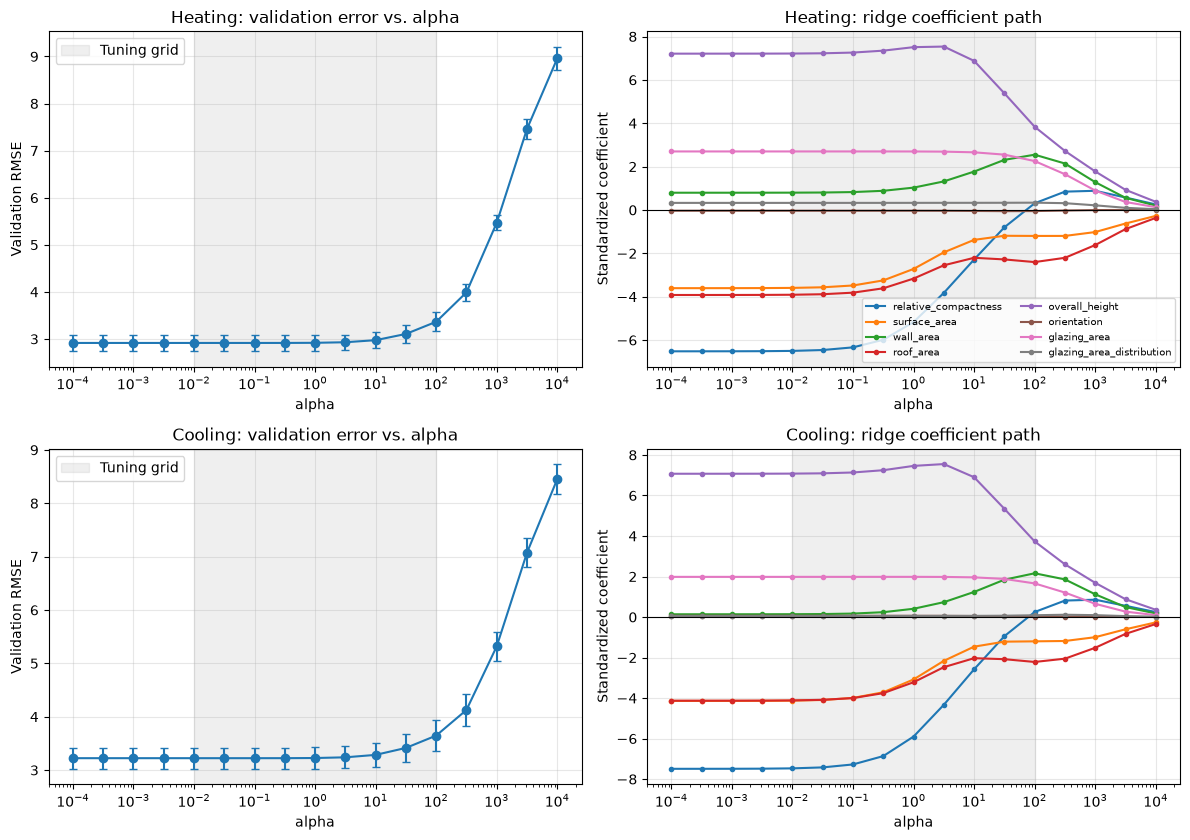

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
mean_coefs = coefs.groupby(["target", "alpha"])[FEATURE_COLUMNS].mean()

for row, target in enumerate(TARGET_COLUMNS):
    ax = axes[row, 0]
    s = sweep_summary[target]
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker="o", capsize=3)
    ax.axvspan(0.01, 100, color="gray", alpha=0.12, label="Tuning grid")
    ax.set(xscale="log", xlabel="alpha", ylabel="Validation RMSE",
           title=f"{TARGET_LABELS[target]}: validation error vs. alpha")
    ax.grid(alpha=0.3)
    ax.legend()

    ax = axes[row, 1]
    path = mean_coefs.loc[target]
    for feature in FEATURE_COLUMNS:
        ax.plot(path.index, path[feature], marker=".", label=feature)
    ax.axvspan(0.01, 100, color="gray", alpha=0.12)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(xscale="log", xlabel="alpha", ylabel="Standardized coefficient",
           title=f"{TARGET_LABELS[target]}: ridge coefficient path")
    ax.grid(alpha=0.3)

axes[0, 1].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "ridge_alpha_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

## Ridge findings

1. **The collinearity is real and exact.** The feature matrix has rank 7 of 8 (condition number about $3 \times 10^{15}$); one eigenvalue of the standardized correlation matrix is exactly zero and two more are small (0.05 and 0.004), all from the geometric features.
2. **Validation error is flat for small penalties and rises after.** Heating RMSE is 2.916 for every alpha up to 0.3, 2.919 at alpha = 1, then +2% at 10, +15% at 100, and +88% at 1000. Cooling follows the same pattern. Inner-CV tuning picked alpha between 0.01 and 1 in all 30 outer folds (5 in notebook 02, 25 in notebook 04): the low end of the grid.
3. **The penalty does stabilize the coefficients, but there was little instability to remove.** The mean across-fold standard deviation of the standardized coefficients falls from 0.19 (alpha ≤ 0.01) to 0.08 at alpha = 10 and 0.04 at alpha = 100, but RMSE rises at the same time. Without a penalty, the largest coefficients (about 4–7 in standardized units) already vary by only about 5% between folds, because the least-squares solver handles the exact collinearity.
4. **Individual geometric coefficients are not interpretable.** Along the path the collinear features trade weight with each other; the relative-compactness coefficient moves from about −6.5 to slightly positive near alpha = 100. Only their combination is determined by the data.
5. **Why ridge cannot help here.** Ridge accepts some bias in exchange for lower variance. With 614 training rows and only 8 features, the linear model's variance is already small, and Part 1 shows its error is bias: the model's form cannot represent the interacting, non-linear shape and glazing effects. A penalty cannot fix bias, so ridge correctly selects almost no penalty and matches linear regression.